In [4]:
from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/Agri-Vision/wheat_leaf"

print("Dataset folders:")
print(os.listdir(dataset_path))

Dataset folders:
['stripe_rust', 'septoria', 'Healthy']


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/Agri-Vision/wheat_leaf"

for folder in os.listdir(dataset_path):
    folder_path = os.path.join(dataset_path, folder)

    if os.path.isdir(folder_path):
        image_count = len(os.listdir(folder_path))
        print(folder, ":", image_count, "images")

stripe_rust : 208 images
septoria : 97 images
Healthy : 102 images


## Step 4: Visualizing Sample Images from the Wheat Dataset

In this step, we display sample images from each class in the wheat leaf dataset.

The dataset contains three classes:
- Healthy
- Septoria
- Stripe Rust

Visualizing the images helps us understand the appearance of each class before preprocessing and model training.


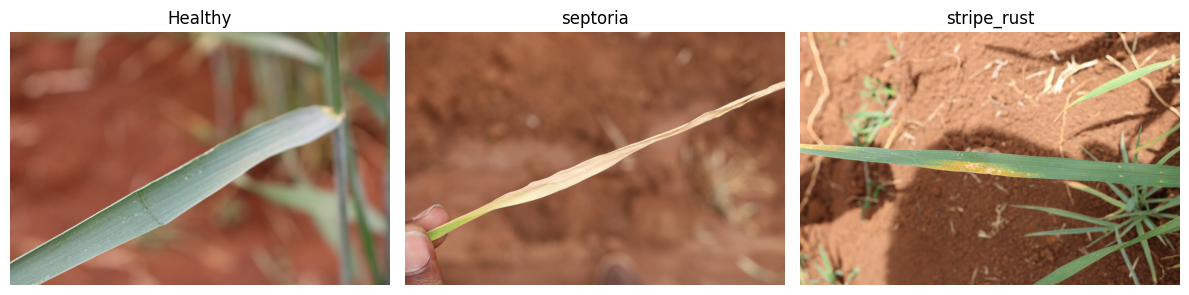

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image

dataset_path = "/content/drive/MyDrive/Agri-Vision/wheat_leaf"

classes = ["Healthy", "septoria", "stripe_rust"]

plt.figure(figsize=(12, 4))

for i, class_name in enumerate(classes):
    class_path = os.path.join(dataset_path, class_name)

    # Get the first image from the class folder
    image_name = os.listdir(class_path)[0]
    image_path = os.path.join(class_path, image_name)

    # Open the image
    image = Image.open(image_path)

    # Display the image
    plt.subplot(1, 3, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

## Step 5: Loading and Splitting the Wheat Dataset

In this step, the wheat leaf dataset is loaded using TensorFlow and divided into three subsets:

- 70% Training data
- 15% Validation data
- 15% Testing data

All images are resized to 224 × 224 pixels.

The training dataset is used to train the model.
The validation dataset is used to monitor model performance during training.
The test dataset is kept separate and is used only for final model evaluation.

In [ ]:
import tensorflow as tf

dataset_path = "/content/drive/MyDrive/Agri-Vision/wheat_leaf"

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

full_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    shuffle=True,
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 407 files belonging to 3 classes.


### Checking the Class Names

The following code displays the class labels automatically detected from the dataset folder names.


In [ ]:
class_names = full_dataset.class_names

print("Class names:", class_names)


Class names: ['Healthy', 'septoria', 'stripe_rust']


### Splitting the Dataset

The complete dataset is divided into training, validation, and testing datasets using a 70:15:15 ratio.

In [ ]:
dataset_size = tf.data.experimental.cardinality(full_dataset).numpy()

train_size = int(0.70 * dataset_size)
validation_size = int(0.15 * dataset_size)

train_dataset = full_dataset.take(train_size)

remaining_dataset = full_dataset.skip(train_size)

validation_dataset = remaining_dataset.take(validation_size)

test_dataset = remaining_dataset.skip(validation_size)

print("Total batches:", dataset_size)
print("Training batches:", tf.data.experimental.cardinality(train_dataset).numpy())
print("Validation batches:", tf.data.experimental.cardinality(validation_dataset).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_dataset).numpy())

Total batches: 26
Training batches: 18
Validation batches: 3
Testing batches: 5


## Step 6: Data Augmentation

The wheat leaf dataset contains a limited number of images.

To improve model generalization and reduce overfitting, data augmentation is applied to the training images.

The augmentation techniques used are:

- Random horizontal flipping
- Random rotation
- Random zoom
- Random contrast adjustment

These transformations create slightly different versions of the original images during training without modifying the original dataset.

In [ ]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
])

### Improving Dataset Loading Performance

The following code uses TensorFlow's prefetch feature.

Prefetching prepares the next batch of images while the model is processing the current batch, which can make training faster.

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

print("Data augmentation created successfully.")
print("Dataset optimization completed.")

Data augmentation created successfully.
Dataset optimization completed.


## Step 7: Building the Wheat Disease Classification Model

In this step, a transfer learning model is created using MobileNetV2.

MobileNetV2 is a pre-trained convolutional neural network that has already learned useful image features from a large image dataset.

For this project:

- MobileNetV2 is used as the base model.
- The pre-trained base layers are initially frozen.
- Data augmentation is applied during training.
- A custom classification layer is added for the three wheat classes:
  - Healthy
  - Septoria
  - Stripe Rust

This approach allows us to train an effective model even with a relatively small dataset.

In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Load the pre-trained MobileNetV2 model
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pre-trained layers
base_model.trainable = False

# Build the complete model
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    layers.Lambda(preprocess_input),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.2),

    layers.Dense(
        len(class_names),
        activation="softmax"
    )
])

print("Model created successfully.")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Model created successfully.


### Viewing the Model Architecture

The following code displays the layers and parameters of the complete wheat disease classification model.

In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Compiling the Model

The model is compiled using:

- Adam optimizer for updating model weights.
- Sparse categorical cross-entropy as the loss function for multi-class classification.
- Accuracy as the main evaluation metric.

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


## Step 8: Training the Wheat Disease Classification Model

In this step, the MobileNetV2-based model is trained using the wheat leaf dataset.

During training:

- The training dataset is used to update the model weights.
- The validation dataset is used to monitor model performance after each epoch.
- The pre-trained MobileNetV2 base layers remain frozen.
- Only the newly added classification layers are trained.

We will initially train the model for 15 epochs.

In [ ]:
EPOCHS = 15

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS
)

Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 134s 7s/step - accuracy: 0.5069 - loss: 1.0056 - val_accuracy: 0.7917 - val_loss: 0.6167
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 74s 4s/step - accuracy: 0.7917 - loss: 0.5147 - val_accuracy: 0.7917 - val_loss: 0.4409
Epoch 3/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 71s 4s/step - accuracy: 0.8750 - loss: 0.3383 - val_accuracy: 0.8750 - val_loss: 0.3711
Epoch 4/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 73s 4s/step - accuracy: 0.9306 - loss: 0.2495 - val_accuracy: 0.8542 - val_loss: 0.2849
Epoch 5/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 71s 4s/step - accuracy: 0.9340 - loss: 0.2453 - val_accuracy: 0.9583 - val_loss: 0.2217
Epoch 6/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 72s 4s/step - accuracy: 0.9549 - loss: 0.1859 - val_accuracy: 0.9375 - val_loss: 0.1667
Epoch 7/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 67s 4s/step - accuracy: 0.9514 - loss: 0.1688 - val_accuracy: 0.9583 - val_loss: 0.1917
Epoch 8/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 66s 4s/step - accuracy: 0.9340 - loss: 0.1646 - val_accuracy: 1.0000 - val_loss

### Displaying the Final Training Results

The following code displays the final training and validation accuracy achieved after the first stage of model training.

In [ ]:
final_train_accuracy = history.history["accuracy"][-1]
final_validation_accuracy = history.history["val_accuracy"][-1]

print(
    "Final Training Accuracy:",
    round(final_train_accuracy * 100, 2),
    "%"
)

print(
    "Final Validation Accuracy:",
    round(final_validation_accuracy * 100, 2),
    "%"
)

Final Training Accuracy: 97.57 %
Final Validation Accuracy: 89.58 %


## Step 9: Saving the Best Model with Model Checkpoint

During model training, Google Colab may disconnect unexpectedly.

To avoid losing the best trained model, ModelCheckpoint is used.

The model is saved whenever the validation accuracy improves.

The saved model can later be loaded and used for:
- Fine-tuning
- Testing
- Backend integration

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint

# Path to save the best model during future training
checkpoint_path = "/content/drive/MyDrive/Agri-Vision/best_wheat_model.keras"

# Create the checkpoint callback
checkpoint = ModelCheckpoint(
    filepath=checkpoint_path,
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

print("Checkpoint created successfully.")

# Save the currently trained model
current_model_path = "/content/drive/MyDrive/Agri-Vision/wheat_model_stage1.keras"

model.save(current_model_path)

print("Current model saved successfully.")
print("Model saved at:", current_model_path)

Checkpoint created successfully.
Current model saved successfully.
Model saved at: /content/drive/MyDrive/Agri-Vision/wheat_model_stage1.keras


## Step 10: Fine-Tuning the MobileNetV2 Model

The first stage of transfer learning achieved good training accuracy, but the validation accuracy can potentially be improved.

In this step:

- The MobileNetV2 base model is unfrozen.
- Most of its layers remain frozen.
- Only the last 20 layers are allowed to learn.
- A very small learning rate is used to avoid damaging the previously learned features.

This process is called fine-tuning.

In [ ]:
# Unfreeze the MobileNetV2 base model
base_model.trainable = True

# Freeze all layers except the last 20 layers
for layer in base_model.layers[:-20]:
    layer.trainable = False

print("Total layers in MobileNetV2:", len(base_model.layers))
print("Fine-tuning the last 20 layers.")

Total layers in MobileNetV2: 154
Fine-tuning the last 20 layers.


### Recompiling the Model for Fine-Tuning

After changing which layers are trainable, the model must be compiled again.

A smaller learning rate is used during fine-tuning to make careful adjustments to the pre-trained weights.

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled successfully for fine-tuning.")

Model recompiled successfully for fine-tuning.


### Fine-Tuning the Model with Checkpoint Protection

In this step, the last 20 layers of MobileNetV2 are fine-tuned.

A small learning rate is used to carefully improve the model.

ModelCheckpoint saves the best model whenever the validation accuracy improves.

EarlyStopping stops training if validation accuracy does not improve for several epochs, helping to reduce overfitting.

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

fine_tune_checkpoint_path = (
    "/content/drive/MyDrive/Agri-Vision/best_wheat_finetuned_model.keras"
)

fine_tune_checkpoint = ModelCheckpoint(
    filepath=fine_tune_checkpoint_path,
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

early_stopping = EarlyStopping(
    monitor="val_accuracy",
    patience=5,
    mode="max",
    restore_best_weights=True,
    verbose=1
)

print("Fine-tuning callbacks created successfully.")

Fine-tuning callbacks created successfully.


### Starting Fine-Tuning

The model is fine-tuned for a maximum of 20 epochs.

Training may stop earlier if the validation accuracy does not improve for 5 consecutive epochs.

In [ ]:
FINE_TUNE_EPOCHS = 20

fine_tune_history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=[
        fine_tune_checkpoint,
        early_stopping
    ]
)

Epoch 1/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9115 - loss: 0.2335
Epoch 1: val_accuracy improved from None to 0.93750, saving model to /content/drive/MyDrive/Agri-Vision/best_wheat_finetuned_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Agri-Vision/best_wheat_finetuned_model.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 82s 4s/step - accuracy: 0.9028 - loss: 0.2400 - val_accuracy: 0.9375 - val_loss: 0.1765
Epoch 2/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9438 - loss: 0.1903
Epoch 2: val_accuracy did not improve from 0.93750
18/18 ━━━━━━━━━━━━━━━━━━━━ 66s 4s/step - accuracy: 0.9271 - loss: 0.2116 - val_accuracy: 0.9375 - val_loss: 0.1310
Epoch 3/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9196 - loss: 0.2175
Epoch 3: val_accuracy did not improve from 0.93750
18/18 ━━━━━━━━━━━━━━━━━━━━ 67s 4s/step - accuracy: 0.9271 - loss: 0.2127 - val_accuracy: 0.9167 - val_loss: 0.2070
Epoch 4/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9

## Step 11: Evaluating the Final Model on Test Data

The fine-tuned model is now evaluated using the test dataset.

The test dataset was not used during training or validation.

This gives a more reliable estimate of how well the model performs on unseen wheat leaf images.

In [ ]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

5/5 ━━━━━━━━━━━━━━━━━━━━ 45s 1s/step - accuracy: 0.9437 - loss: 0.1027
Test Loss: 0.1027
Test Accuracy: 94.37 %


## Step 12: Evaluating Class-wise Model Performance

In this step, predictions are generated for the test dataset.

A confusion matrix is used to show how many images from each class are predicted correctly or incorrectly.

This helps identify which wheat disease classes are being confused by the model.

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt

# Store true labels and predicted labels
y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = model.predict(images, verbose=0)

    predicted_labels = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Predictions generated successfully.")

Predictions generated successfully.


### Confusion Matrix

The confusion matrix compares the actual class labels with the predicted class labels.

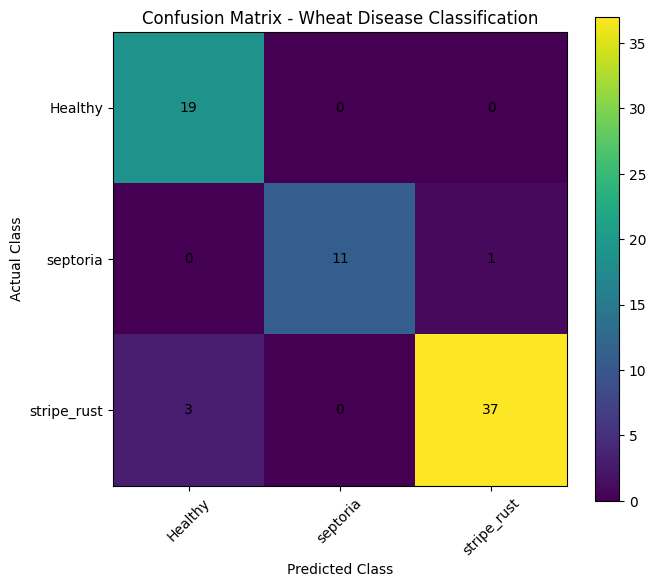

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 6))

plt.imshow(cm)

plt.title("Confusion Matrix - Wheat Disease Classification")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    range(len(class_names)),
    class_names,
    rotation=45
)

plt.yticks(
    range(len(class_names)),
    class_names
)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

### Classification Report

The classification report displays precision, recall, F1-score, and accuracy for each wheat class.

In [ ]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

     Healthy       0.86      1.00      0.93        19
    septoria       1.00      0.92      0.96        12
 stripe_rust       0.97      0.93      0.95        40

    accuracy                           0.94        71
   macro avg       0.95      0.95      0.94        71
weighted avg       0.95      0.94      0.94        71



## Step 14: Saving the Final Trained Model

The final fine-tuned wheat disease classification model is saved to Google Drive.

This model will later be downloaded and integrated into the FastAPI backend.

The class names are also saved so the backend can correctly convert model predictions into readable labels.

In [ ]:
import json

# Final model path
final_model_path = (
    "/content/drive/MyDrive/Agri-Vision/final_wheat_model.keras"
)

# Save the final model
model.save(final_model_path)

print("Final model saved successfully.")
print("Model path:", final_model_path)


# Save class names
class_names_path = (
    "/content/drive/MyDrive/Agri-Vision/class_names.json"
)

with open(class_names_path, "w") as file:
    json.dump(class_names, file)

print("Class names saved successfully.")
print("Class names:", class_names)
print("Class names path:", class_names_path)

Final model saved successfully.
Model path: /content/drive/MyDrive/Agri-Vision/final_wheat_model.keras
Class names saved successfully.
Class names: ['Healthy', 'septoria', 'stripe_rust']
Class names path: /content/drive/MyDrive/Agri-Vision/class_names.json


## Rebuilding the Trained Model for Weight Recovery

In [5]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
])

base_model_rebuilt = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model_rebuilt.trainable = True

for layer in base_model_rebuilt.layers[:-20]:
    layer.trainable = False

old_model_rebuilt = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Lambda(preprocess_input),
    base_model_rebuilt,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(3, activation="softmax")
])

checkpoint_path = (
    "/content/drive/MyDrive/Agri-Vision/"
    "best_wheat_finetuned_model.keras"
)

old_model_rebuilt.load_weights(checkpoint_path)

print("Trained weights loaded successfully.")

Trained weights loaded successfully.


## Step 20: Creating a Clean Inference Model

The training model contains data augmentation and preprocessing layers.

For deployment, we create a clean inference model that:

- Accepts a 224 × 224 RGB image
- Uses the trained MobileNetV2 base model
- Uses the trained classification layer
- Does not include data augmentation
- Does not include a Lambda preprocessing layer

Image preprocessing will be handled manually in the FastAPI backend.

In [ ]:
from tensorflow.keras import layers, models

# Create a clean inference model
inference_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.2),

    layers.Dense(
        3,
        activation="softmax"
    )
])

print("Clean inference model created successfully.")

Clean inference model created successfully.


In [ ]:
# Copy MobileNetV2 trained weights
inference_model.layers[0].set_weights(
    old_model_rebuilt.layers[2].get_weights()
)

# Copy final Dense layer weights
inference_model.layers[-1].set_weights(
    old_model_rebuilt.layers[-1].get_weights()
)

print("Trained weights copied to inference model successfully.")

Trained weights copied to inference model successfully.


### Testing the Clean Inference Model

The clean inference model is tested on a known Healthy wheat image before exporting it to the backend.

In [ ]:
import numpy as np
from PIL import Image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

image_path = (
    "/content/drive/MyDrive/Agri-Vision/"
    "wheat_leaf/Healthy/loh(3).JPG"
)

image = Image.open(image_path).convert("RGB")
image = image.resize((224, 224))

image_array = np.array(
    image,
    dtype=np.float32
)

image_array = np.expand_dims(
    image_array,
    axis=0
)

image_array = preprocess_input(
    image_array
)

predictions = inference_model.predict(
    image_array,
    verbose=0
)

predicted_index = int(
    np.argmax(predictions[0])
)

predicted_class = class_names[
    predicted_index
]

confidence = float(
    predictions[0][predicted_index]
) * 100

print("Prediction:", predicted_class)
print("Confidence:", round(confidence, 2), "%")
print("All probabilities:", predictions[0])

Prediction: Healthy
Confidence: 87.97 %
All probabilities: [8.7966770e-01 4.7708279e-04 1.1985516e-01]


### Exporting the Final Inference Model

The clean inference model has been tested successfully.

This model does not contain data augmentation or Lambda preprocessing layers, making it suitable for FastAPI backend deployment.

In [ ]:
final_inference_model_path = (
    "/content/drive/MyDrive/Agri-Vision/"
    "final_wheat_inference_model.keras"
)

inference_model.save(
    final_inference_model_path
)

print("Final inference model saved successfully.")
print(
    "Model path:",
    final_inference_model_path
)

Final inference model saved successfully.
Model path: /content/drive/MyDrive/Agri-Vision/final_wheat_inference_model.keras
